**Fetal Head Ultrasound: Data Preparation and EDA**

This notebook gets the HC18 ultrasound dataset ready for head segmentation. It downloads the files, turns the doctors' head outlines into filled masks, splits the images into train, validation and test, and then looks at what the data is actually like. Everything it saves goes into one shared folder so the modeling and measurement notebooks read exactly the same files.

In [1]:
import hashlib
import os
import subprocess
import sys
import urllib.request
import zipfile
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams["figure.dpi"] = 70  # keeps the saved notebook small

**Setup**

All paths and constants live in this one cell so nothing is hard coded further down. On Colab the data folder sits on the shared Google Drive, because the masks and the split file have to be visible to the whole team and not just to my session. The random seed is fixed so that rerunning the notebook always gives the same split and the same sample images.

In [2]:
SEED = 42
SPLIT_FRACTIONS = {"train": 0.70, "val": 0.15, "test": 0.15}
REPO_URL = (
    "https://github.com/aladenisun/"
    "aai-521-ultrasound-fetal-head-circumference.git"
)
ZENODO_URL = "https://zenodo.org/records/1327317/files/{name}?download=1"
ZENODO_FILES = {
    "training_set.zip": "00eb8198b9a505b2b3a6dfc740382497",
    "training_set_pixel_size_and_HC.csv": "c0761518fece2bd2d2ad4218f2cd9777",
    "test_set.zip": "8402af5d137ef40a2888c1011ef3fe7e",
    "test_set_pixel_size.csv": "8476dc198cc6542f26c57e87faeee033",
}

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    # Change this if the shared team folder has a different name.
    DATA_DIR = Path("/content/drive/MyDrive/aai-521-hc18")
    REPO_DIR = Path("/content/aai-521-ultrasound-fetal-head-circumference")
    if not REPO_DIR.exists():
        subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)
else:
    cwd = Path.cwd()
    REPO_DIR = cwd.parent if cwd.name == "notebooks" else cwd
    DATA_DIR = Path(os.environ.get("HC18_DATA_DIR", REPO_DIR / "data"))

RAW_DIR = DATA_DIR / "raw"
IMAGE_DIR = RAW_DIR / "training_set"
MASK_DIR = DATA_DIR / "masks"
FIGURE_DIR = DATA_DIR / "figures"
SPLITS_PATH = DATA_DIR / "splits.csv"
LABELS_PATH = RAW_DIR / "training_set_pixel_size_and_HC.csv"

for folder in (RAW_DIR, MASK_DIR, FIGURE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(REPO_DIR / "src"))
print(f"Data folder: {DATA_DIR}")

Data folder: /home/claude/hc18


**Downloading HC18**

The files come straight from Zenodo and each one is checked against the MD5 hash listed on the dataset page, so a broken download gets caught here instead of showing up later as a strange image. Files that are already in the folder are skipped, which means only the first run pays for the download. I also pull the official test set for completeness, but it has no outlines, so every split in this project is cut from the 999 labeled training images.

In [3]:
def md5_of(path, chunk_size=1 << 20):
    """Return the MD5 hex digest of a file."""
    digest = hashlib.md5()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


def download_hc18(raw_dir):
    """Download and unzip the HC18 files that are not already present."""
    for name, expected_md5 in ZENODO_FILES.items():
        target = raw_dir / name
        extracted = raw_dir / name.replace(".zip", "")
        if target.exists() or (name.endswith(".zip") and extracted.exists()):
            print(f"Already have {name}")
        else:
            print(f"Downloading {name} ...")
            urllib.request.urlretrieve(ZENODO_URL.format(name=name), target)
            if md5_of(target) != expected_md5:
                raise IOError(f"MD5 mismatch for {name}, download again")
        if name.endswith(".zip") and not extracted.exists():
            with zipfile.ZipFile(target) as archive:
                archive.extractall(raw_dir)


download_hc18(RAW_DIR)

Already have training_set.zip
Already have training_set_pixel_size_and_HC.csv
Already have test_set.zip
Already have test_set_pixel_size.csv


**Loading the label table**

The CSV that ships with the dataset has one row per image with the pixel size and the head circumference the doctors measured. I rename the columns to short names without spaces because these same names end up in the split file everyone else reads. The file check makes sure every row has both an ultrasound image and an outline image before any processing starts.

In [4]:
labels = pd.read_csv(LABELS_PATH)
labels.columns = ["filename", "pixel_size_mm", "true_hc_mm"]
labels["filename"] = labels["filename"].str.strip()


def annotation_path(filename):
    """Return the path of the outline image that belongs to an image."""
    return IMAGE_DIR / filename.replace(".png", "_Annotation.png")


missing = [
    name for name in labels["filename"]
    if not (IMAGE_DIR / name).exists() or not annotation_path(name).exists()
]
print(f"Rows in label table: {len(labels)}")
print(f"Rows with a missing image or outline: {len(missing)}")
assert not missing, missing[:5]
labels.head()

Rows in label table: 999
Rows with a missing image or outline: 0


,filename,pixel_size_mm,true_hc_mm
0,000_HC.png,0.069136,44.30
1,001_HC.png,0.089659,56.81
2,002_HC.png,0.062033,68.75
3,003_HC.png,0.091291,69.00
4,004_HC.png,0.061240,59.81


**Turning outlines into filled masks**

The doctors' annotation is only a thin ellipse line, but a segmentation model needs every head pixel labeled, so I fill the inside of each outline. Filling the outer contour works whenever the line is a closed loop. If a head runs off the edge of the image the line is not closed and the fill would only color the line itself, so in that case I fit an ellipse to the line and fill that instead.

In [5]:
MIN_FILL_RATIO = 3  # a filled head is far bigger than its own outline


def outline_to_mask(outline):
    """Convert an outline image into a filled binary mask.

    Returns the mask (uint8, head = 1) and the name of the method used.
    """
    line = (outline > 127).astype(np.uint8)
    contours, _ = cv2.findContours(
        line, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    mask = np.zeros_like(line)
    cv2.drawContours(mask, contours, -1, color=1, thickness=cv2.FILLED)
    if mask.sum() >= MIN_FILL_RATIO * line.sum():
        return mask, "contour_fill"

    # Open outline: fall back to a fitted ellipse, clipped by the image.
    ellipse = cv2.fitEllipse(cv2.findNonZero(line))
    mask = np.zeros_like(line)
    cv2.ellipse(mask, ellipse, color=1, thickness=cv2.FILLED)
    return mask, "ellipse_fit"


def ellipse_circumference(semi_major, semi_minor):
    """Ramanujan's approximation of the circumference of an ellipse."""
    h = ((semi_major - semi_minor) / (semi_major + semi_minor)) ** 2
    return np.pi * (semi_major + semi_minor) * (
        1 + 3 * h / (10 + np.sqrt(4 - 3 * h)))


def mask_circumference_px(mask):
    """Circumference in pixels of an ellipse fitted to the mask edge."""
    contours, _ = cv2.findContours(
        mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    points = max(contours, key=cv2.contourArea).reshape(-1, 2)
    height, width = mask.shape
    inside = (
        (points[:, 0] > 0) & (points[:, 0] < width - 1)
        & (points[:, 1] > 0) & (points[:, 1] < height - 1)
    )
    _, axes, _ = cv2.fitEllipse(points[inside])
    return ellipse_circumference(axes[0] / 2, axes[1] / 2)


def touches_border(mask):
    """True if any head pixel lies on the edge of the image."""
    return bool(
        mask[0].any() or mask[-1].any()
        or mask[:, 0].any() or mask[:, -1].any())


def process_image(row):
    """Create and save the mask for one image and return its statistics."""
    raw_bytes = (IMAGE_DIR / row.filename).read_bytes()
    image = cv2.imdecode(
        np.frombuffer(raw_bytes, np.uint8), cv2.IMREAD_UNCHANGED)
    outline = cv2.imread(
        str(annotation_path(row.filename)), cv2.IMREAD_GRAYSCALE)
    mask, method = outline_to_mask(outline)
    cv2.imwrite(str(MASK_DIR / row.filename), mask * 255)

    gray = image if image.ndim == 2 else cv2.cvtColor(
        image, cv2.COLOR_BGR2GRAY)
    skull_band = cv2.dilate(outline, np.ones((5, 5), np.uint8)) > 127
    return {
        "filename": row.filename,
        "height": image.shape[0],
        "width": image.shape[1],
        "channels": 1 if image.ndim == 2 else image.shape[2],
        "dtype": str(image.dtype),
        "md5": hashlib.md5(raw_bytes).hexdigest(),
        "fill_method": method,
        "mask_fraction": mask.mean(),
        "touches_border": touches_border(mask),
        "skull_contrast": gray[skull_band].mean() - gray.mean(),
        "mask_hc_mm": mask_circumference_px(mask) * row.pixel_size_mm,
    }


stats = pd.DataFrame([process_image(row) for row in labels.itertuples()])
data = labels.merge(stats, on="filename")
print(f"Masks written to {MASK_DIR}: {len(data)}")
print(data["fill_method"].value_counts().to_string())

Masks written to /home/claude/hc18/masks: 999
fill_method
contour_fill    995
ellipse_fit       4


**Checking 20 random masks by eye**

Numbers alone would not tell me if a mask landed in the wrong place, so I draw the mask edge over the ultrasound for 20 randomly picked images. The red line should sit right on the skull in every panel. The masks are stored as 0 and 255 so they are visible when opened as normal images, and the data loader turns them back into 0 and 1.

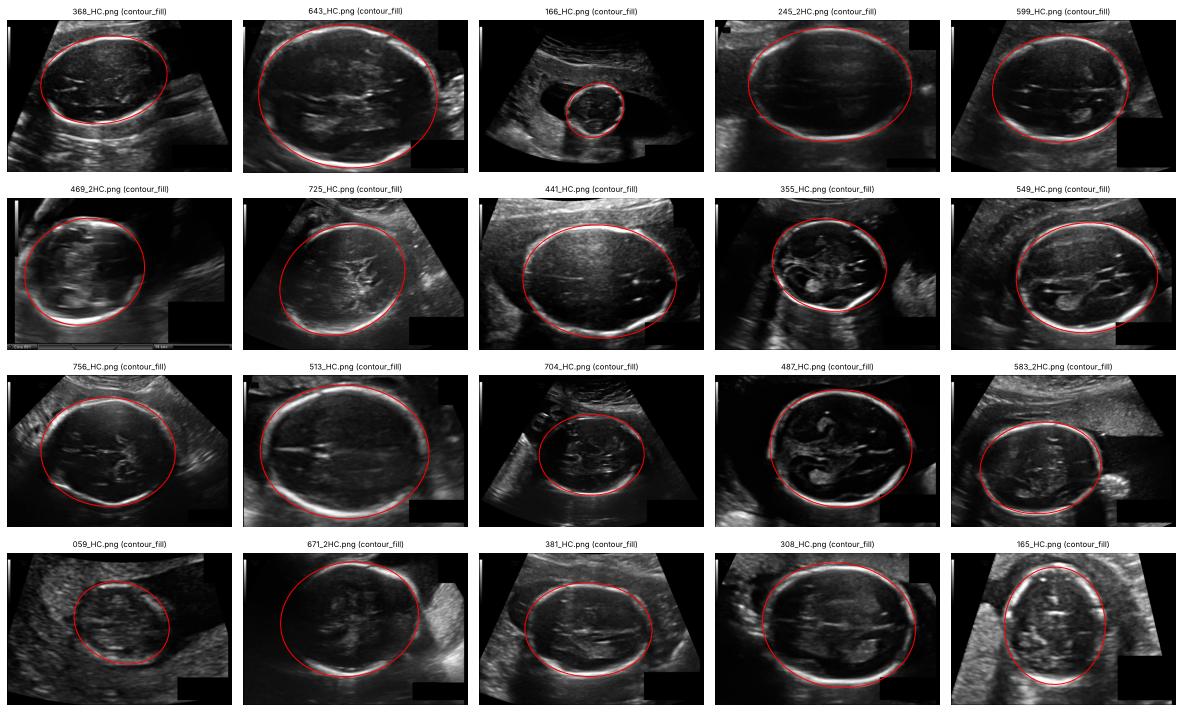

In [6]:
def load_pair(filename):
    """Read an ultrasound image and its saved mask (0 or 1)."""
    image = cv2.imread(str(IMAGE_DIR / filename), cv2.IMREAD_GRAYSCALE)
    mask = cv2.imread(str(MASK_DIR / filename), cv2.IMREAD_GRAYSCALE)
    return image, (mask > 127).astype(np.uint8)


def show_overlays(filenames, titles, n_cols, save_as):
    """Plot images with the mask edge drawn on top and save the figure."""
    n_rows = int(np.ceil(len(filenames) / n_cols))
    fig, axes = plt.subplots(
        n_rows, n_cols, figsize=(3.4 * n_cols, 2.6 * n_rows))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, filename, title in zip(axes.ravel(), filenames, titles):
        image, mask = load_pair(filename)
        ax.imshow(image, cmap="gray")
        ax.contour(mask, levels=[0.5], colors="red", linewidths=1)
        ax.set_title(title, fontsize=8)
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / save_as, dpi=150, bbox_inches="tight")
    plt.show()


check = data.sample(n=min(20, len(data)), random_state=SEED)
show_overlays(
    check["filename"],
    check["filename"] + " (" + check["fill_method"] + ")",
    n_cols=5,
    save_as="mask_check_20_random.png",
)

**Checking the masks against the doctors' measurements**

As a second check I fit an ellipse to each mask, convert its circumference to millimeters with the pixel size, and compare it to the value in the CSV. If the masks and pixel sizes are right, the two numbers should agree to within a millimeter or two. A large gap on any image would point to a bad fill or a pixel size problem, and it is better to find that now than after a model has been trained on it.

In [7]:
data["hc_error_mm"] = data["mask_hc_mm"] - data["true_hc_mm"]
abs_error = data["hc_error_mm"].abs()
print(f"Mean absolute difference:   {abs_error.mean():.2f} mm")
print(f"Median absolute difference: {abs_error.median():.2f} mm")
print(f"Mean signed difference:     {data['hc_error_mm'].mean():+.2f} mm")
print(f"Largest absolute difference: {abs_error.max():.2f} mm")
print(f"Images off by more than 2 mm: {(abs_error > 2).sum()}")
data.loc[abs_error.nlargest(5).index, [
    "filename", "fill_method", "touches_border",
    "true_hc_mm", "mask_hc_mm", "hc_error_mm"]]

Mean absolute difference:   0.71 mm
Median absolute difference: 0.66 mm
Mean signed difference:     +0.71 mm
Largest absolute difference: 2.01 mm
Images off by more than 2 mm: 1


,filename,fill_method,touches_border,true_hc_mm,mask_hc_mm,hc_error_mm
786,637_HC.png,contour_fill,False,172.69,174.697145,2.007145
932,754_HC.png,contour_fill,False,291.30,293.109588,1.809588
835,677_HC.png,contour_fill,False,245.30,246.995532,1.695532
862,701_HC.png,contour_fill,False,283.50,285.177779,1.677779
963,779_HC.png,contour_fill,False,296.76,298.434282,1.674282


**What the mask checks showed**

All 999 masks were created, 995 by filling the closed outline and 4 by the ellipse fallback. In the 20 images I looked at, the red edge sits on the skull every time. The mask circumference comes out about 0.7 mm larger than the doctors' value on average and 2.0 mm at worst, and it is always larger, which makes sense because the filled mask includes the thickness of the drawn line.

**Train, validation and test split**

Some filenames share the same leading number, such as *010_HC* and *010_2HC*, which looks like more than one image of the same fetus. I split by that number instead of by image, because near duplicate images on both sides of the split would make validation and test scores look better than they really are. The groups are shuffled with the fixed seed and assigned in order until roughly 70, 15 and 15 percent of the images are reached.

In [8]:
def make_splits(table, fractions, seed):
    """Assign each image to a split, keeping each fetus in one split."""
    table = table.copy()
    table["fetus_id"] = table["filename"].str.split("_").str[0]
    group_sizes = table.groupby("fetus_id").size()

    rng = np.random.default_rng(seed)
    shuffled_ids = rng.permutation(np.sort(group_sizes.index.to_numpy()))
    share_before = (
        group_sizes[shuffled_ids].cumsum() - group_sizes[shuffled_ids]
    ) / len(table)

    train_end = fractions["train"]
    val_end = train_end + fractions["val"]
    split_of_id = pd.Series("test", index=shuffled_ids)
    split_of_id[share_before.to_numpy() < val_end] = "val"
    split_of_id[share_before.to_numpy() < train_end] = "train"
    table["split"] = table["fetus_id"].map(split_of_id)
    return table


data = make_splits(data, SPLIT_FRACTIONS, SEED)
assert data.groupby("fetus_id")["split"].nunique().max() == 1

splits = data[["filename", "split", "pixel_size_mm", "true_hc_mm"]]
splits.to_csv(SPLITS_PATH, index=False)

summary = data.groupby("split").agg(
    images=("filename", "size"),
    fetuses=("fetus_id", "nunique"),
    mean_hc_mm=("true_hc_mm", "mean"),
).loc[list(SPLIT_FRACTIONS)]
summary["share"] = (summary["images"] / len(data)).round(3)

images_per_fetus = data.groupby("fetus_id").size()
identical = data[data.duplicated("md5", keep=False)]
print(f"Fetuses: {len(images_per_fetus)}, with more than one image: "
      f"{(images_per_fetus > 1).sum()}")
print(f"Byte for byte identical images: "
      f"{sorted(identical['filename'])}")
print(f"Saved {SPLITS_PATH}")
summary

Fetuses: 806, with more than one image: 164
Byte for byte identical images: ['392_2HC.png', '392_HC.png']
Saved /home/claude/hc18/splits.csv


,images,fetuses,mean_hc_mm,share
split,,,,
train,700,556,173.639000,0.701
val,150,125,176.932533,0.150
test,149,125,175.312282,0.149


**How the split came out**

The split landed on 700, 150 and 149 images, so grouping by fetus cost almost nothing against the 70, 15 and 15 percent target. Of the 806 fetuses, 164 have more than one image, and one pair of files is byte for byte identical. Both of those would have leaked between splits with a plain random split by image.

**Image sizes and pixel sizes**

The model needs every input to be the same shape, so I check if the raw images already are or if the loader has to deal with mixed sizes. Pixel size matters just as much here, because it is what turns a circumference in pixels into millimeters, and it changes from scan to scan with the zoom level. That is why it is carried into the split file for every image.

Image shapes (height, width, channels, dtype):
height  width  channels  dtype
539     780    1         uint8      1
        790    1         uint8      1
540     789    1         uint8      1
        800    1         uint8    975
541     738    1         uint8      1
        783    1         uint8      1
        797    1         uint8      1
        798    1         uint8      1
542     782    1         uint8      1
        786    1         uint8      1
        796    1         uint8      1
        800    1         uint8      5
543     783    1         uint8      1
        794    1         uint8      1
544     780    1         uint8      1
        791    1         uint8      1
        794    1         uint8      1
        796    1         uint8      1
545     788    1         uint8      1
        789    1         uint8      1
563     799    1         uint8      1

count    999.0000
mean       0.1398
std        0.0530
min        0.0494
25%        0.1088
50%        0.1284
75%        0.15

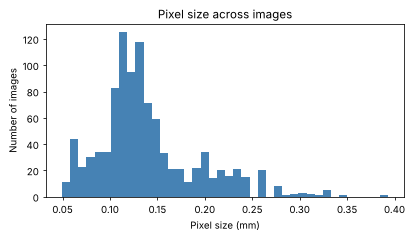

In [9]:
print("Image shapes (height, width, channels, dtype):")
print(data.groupby(["height", "width", "channels", "dtype"]).size()
      .rename("images").to_string())
print()
print(data["pixel_size_mm"].describe().round(4).to_string())

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(data["pixel_size_mm"], bins=40, color="steelblue")
ax.set_xlabel("Pixel size (mm)")
ax.set_ylabel("Number of images")
ax.set_title("Pixel size across images")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "pixel_size_histogram.png", dpi=150)
plt.show()

**What the sizes showed**

Most images are 800 by 540 pixels, but 24 of the 999 are a few pixels off, and all of them are single channel 8 bit. Since the loader resizes everything to one size anyway, the odd ones need no special handling. Pixel size runs from about 0.05 to 0.39 mm, so two heads that look the same size on screen can be very different in millimeters.

**Head circumference distribution**

The head circumference is the number the whole project is trying to predict, so I want to see its range and if any sizes are rare. The second plot overlays the three splits, since a test set that happened to hold mostly small or mostly large heads would not be a fair test. The curves are drawn as densities so the smaller validation and test sets can be compared with the training set directly.

count    999.0
mean     174.4
std       65.3
min       44.3
25%      153.6
50%      174.1
75%      189.8
max      346.4

Share of each head size group per split:
size_group  under 100 mm  100 to 200 mm  over 200 mm
split                                               
train               0.19           0.59         0.22
val                 0.13           0.67         0.20
test                0.19           0.60         0.21


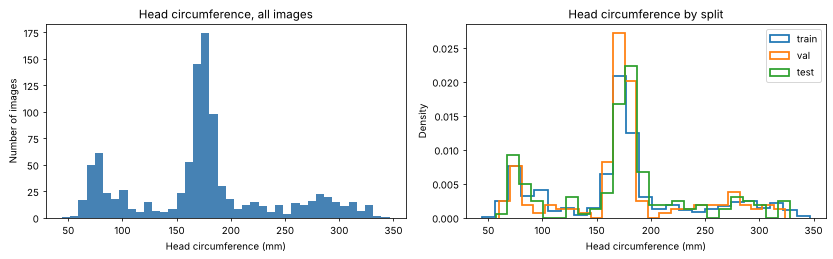

In [10]:
print(data["true_hc_mm"].describe().round(1).to_string())

data["size_group"] = pd.cut(
    data["true_hc_mm"], bins=[0, 100, 200, 400],
    labels=["under 100 mm", "100 to 200 mm", "over 200 mm"])
print()
print("Share of each head size group per split:")
print(pd.crosstab(data["split"], data["size_group"], normalize="index")
      .loc[list(SPLIT_FRACTIONS)].round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(data["true_hc_mm"], bins=40, color="steelblue")
axes[0].set_title("Head circumference, all images")
axes[0].set_ylabel("Number of images")
for name in SPLIT_FRACTIONS:
    axes[1].hist(
        data.loc[data["split"] == name, "true_hc_mm"],
        bins=25, density=True, histtype="step", linewidth=1.8, label=name)
axes[1].set_title("Head circumference by split")
axes[1].set_ylabel("Density")
axes[1].legend()
for ax in axes:
    ax.set_xlabel("Head circumference (mm)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "head_circumference_histograms.png", dpi=150)
plt.show()

**What the distribution showed**

Head sizes are not evenly spread: about 60 percent of the images fall between 100 and 200 mm with a sharp peak near 175 mm, while 18 percent are under 100 mm and 22 percent are over 200 mm. The three splits follow the same overall shape, although validation has fewer small heads than train and test, 13 percent against 19 percent. Scores on the smallest heads will rest on few images, so it is worth reporting error by size group and not only as one average.

**Sample images with outlines**

This grid shows twelve images picked at even steps from the smallest head to the largest, with the doctors' outline in red. Picking them this way, instead of at random, shows how different the scans look at different stages of pregnancy. It also gives a quick sense of how much of the frame the head fills, which matters once everything is shrunk to the model's input size.

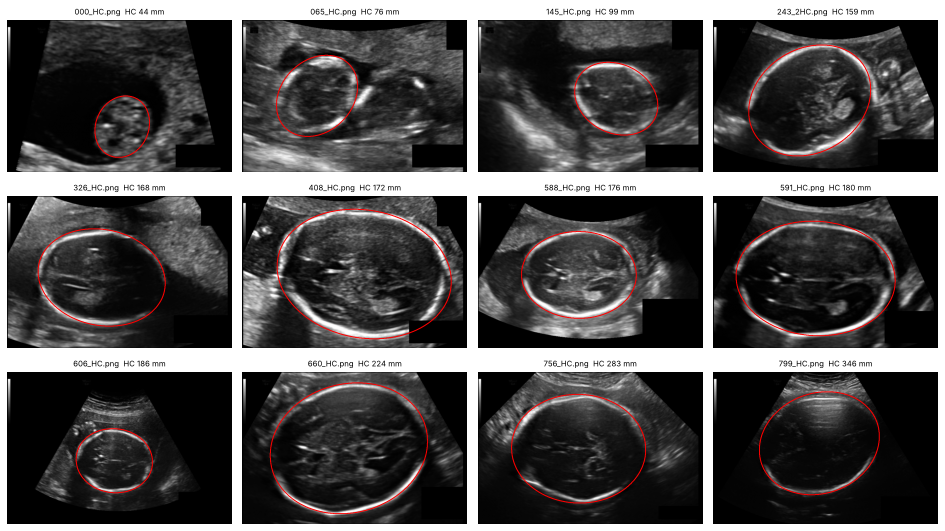

In [11]:
ordered = data.sort_values("true_hc_mm").reset_index(drop=True)
picks = ordered.iloc[np.linspace(0, len(ordered) - 1, 12).astype(int)]
show_overlays(
    picks["filename"],
    [f"{row.filename}  HC {row.true_hc_mm:.0f} mm"
     for row in picks.itertuples()],
    n_cols=4,
    save_as="sample_grid_by_head_size.png",
)

**Image quality problems**

Two problems can be measured directly, so I count them instead of only eyeballing them. A head is flagged as cut off when its mask touches the edge of the image, and skull contrast is the average brightness along the outline minus the average brightness of the whole image, so a low value means a faint skull edge. The panels show the faintest skull edges and the cut off heads, which are the images I would expect a model to struggle with most.

Heads touching the image edge: 5 of 999
split
test     1
train    3
val      1

Skull contrast (0 to 255 gray levels):
count    999.0
mean      55.6
std       21.1
min      -20.6
25%       43.5
50%       57.4
75%       69.9
max      114.4

size_group
under 100 mm     31.3
100 to 200 mm    63.6
over 200 mm      54.1


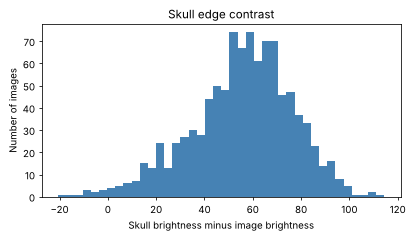

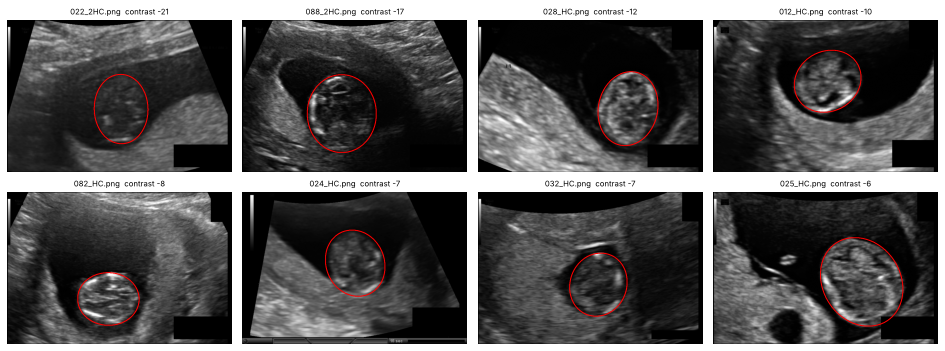

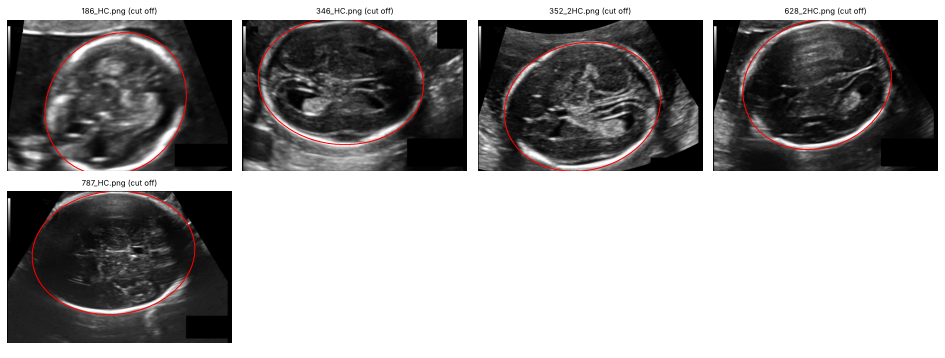

In [12]:
n_cut_off = int(data["touches_border"].sum())
print(f"Heads touching the image edge: {n_cut_off} of {len(data)}")
print(data.groupby("split")["touches_border"].sum()
      .rename("cut off heads per split").to_string())
print()
print("Skull contrast (0 to 255 gray levels):")
print(data["skull_contrast"].describe().round(1).to_string())
print()
print(data.groupby("size_group", observed=True)["skull_contrast"].mean()
      .round(1).rename("mean skull contrast by head size").to_string())

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(data["skull_contrast"], bins=40, color="steelblue")
ax.set_xlabel("Skull brightness minus image brightness")
ax.set_ylabel("Number of images")
ax.set_title("Skull edge contrast")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "skull_contrast_histogram.png", dpi=150)
plt.show()

faint = data.nsmallest(8, "skull_contrast")
show_overlays(
    faint["filename"],
    [f"{row.filename}  contrast {row.skull_contrast:.0f}"
     for row in faint.itertuples()],
    n_cols=4,
    save_as="faintest_skull_edges.png",
)

cut_off = data[data["touches_border"]].head(8)
if len(cut_off):
    show_overlays(
        cut_off["filename"],
        cut_off["filename"] + " (cut off)",
        n_cols=4,
        save_as="heads_cut_off.png",
    )

**What the quality checks showed**

Cut off heads are rare, only 5 of 999, so they are not a big risk for training. Faint skull edges are mostly a small head problem: average skull contrast is 31 gray levels for heads under 100 mm against 64 for the middle group, and the eight faintest images are all early scans where the skull barely stands out from the tissue around it. Looking through the grids, the skull is also usually bright at the top and bottom but fades along the sides, and many frames carry a scale bar and blacked out boxes in the corners that the model will have to learn to ignore.

**Data loader check**

The loader lives in *src/dataset.py* so the training notebooks can import it instead of copying code. Here I pull one augmented training batch and draw the mask edge over each image, because the easiest augmentation bug to make is flipping or rotating the image without doing the same to its mask. The asserts confirm the shapes match and that the masks are still strictly 0 and 1 after resizing and rotation.

{'train': 700, 'val': 150, 'test': 149}
Batch shape: (8, 1, 256, 256), mask values: [0.0, 1.0]


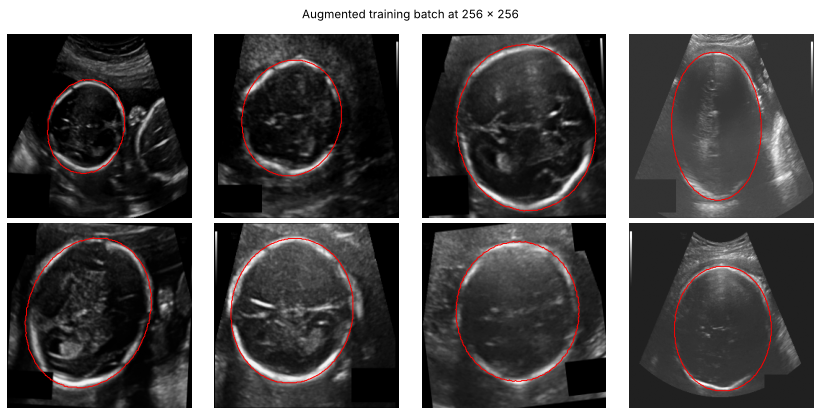

In [13]:
import torch  # noqa: E402

from dataset import get_dataloaders  # noqa: E402

torch.manual_seed(SEED)
loaders = get_dataloaders(
    DATA_DIR, image_size=256, batch_size=8, augment=True, num_workers=0)
images, masks = next(iter(loaders["train"]))

assert images.shape == masks.shape == (len(images), 1, 256, 256)
assert set(masks.unique().tolist()) <= {0.0, 1.0}
assert 0.0 <= images.min() and images.max() <= 1.0
print({name: len(loader.dataset) for name, loader in loaders.items()})
print(f"Batch shape: {tuple(images.shape)}, mask values: "
      f"{masks.unique().tolist()}")

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, image, mask in zip(axes.ravel(), images, masks):
    ax.imshow(image[0], cmap="gray", vmin=0, vmax=1)
    ax.contour(mask[0], levels=[0.5], colors="red", linewidths=1)
    ax.axis("off")
fig.suptitle("Augmented training batch at 256 x 256")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "augmented_batch.png", dpi=150)
plt.show()

**What gets handed off**

The modeling and measurement work only needs three things from this notebook: the split file, the masks folder, and the data loader. One thing to keep in mind is that resizing to a square changes the shape of the head, so a predicted mask has to be resized back to the original image size before its circumference is converted to millimeters. The loader can return the original size and pixel size with each image for exactly that reason.

In [14]:
print(f"Split file:  {SPLITS_PATH}")
print(f"Masks:       {MASK_DIR} ({len(list(MASK_DIR.glob('*.png')))} files)")
print(f"Figures:     {FIGURE_DIR}")
print(f"Data loader: {REPO_DIR / 'src' / 'dataset.py'}")

Split file:  /home/claude/hc18/splits.csv
Masks:       /home/claude/hc18/masks (999 files)
Figures:     /home/claude/hc18/figures
Data loader: /home/claude/repo/src/dataset.py
